In [1]:
import os
print(os.listdir('../data/raw'))

['.ipynb_checkpoints', 'heart-disease.names', 'processed.cleveland.data']


In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib, warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

cols = ['age','sex','cp','trestbps','chol','fbs','restecg',
        'thalach','exang','oldpeak','slope','ca','thal','num']

# header=None: file mein column names nahi; na_values='?': '?' = missing
df = pd.read_csv('../data/raw/processed.cleveland.data',
                 header=None, names=cols, na_values='?')
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [8]:
df.info()
print('\nMissing values:\n', df.isnull().sum()[df.isnull().sum() > 0])
print('\nDuplicates:', df.duplicated().sum())
df.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing values:
 ca      4
thal    2
dtype: int64

Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


In [9]:
df['target'] = (df['num'] > 0).astype(int)
print(df['target'].value_counts())
print((df['target'].value_counts(normalize=True) * 100).round(1))
df[df.isnull().any(axis=1)]

target
0    164
1    139
Name: count, dtype: int64
target
0    54.1
1    45.9
Name: proportion, dtype: float64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2,1
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0,0


In [10]:
num_cols = ['age','trestbps','chol','thalach','oldpeak']
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f'{c}: {n} outliers')

age: 0 outliers
trestbps: 9 outliers
chol: 5 outliers
thalach: 1 outliers
oldpeak: 5 outliers


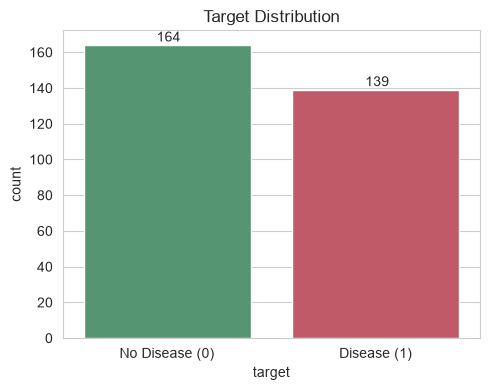

In [11]:
#EDA

plt.figure(figsize=(5,4))
ax = sns.countplot(x='target', data=df, palette=['#4C9F70','#D1495B'])
ax.set_xticklabels(['No Disease (0)','Disease (1)'])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+0.35, p.get_height()+2))
plt.title('Target Distribution'); plt.tight_layout()
plt.savefig('../images/eda/01_target_distribution.png', dpi=150); plt.show()

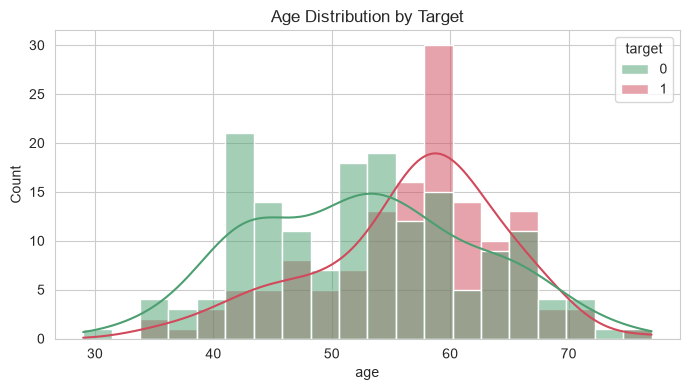

In [12]:
plt.figure(figsize=(7,4))
sns.histplot(data=df, x='age', hue='target', kde=True, bins=20, palette=['#4C9F70','#D1495B'])
plt.title('Age Distribution by Target'); plt.tight_layout()
plt.savefig('../images/eda/02_age_by_target.png', dpi=150); plt.show()

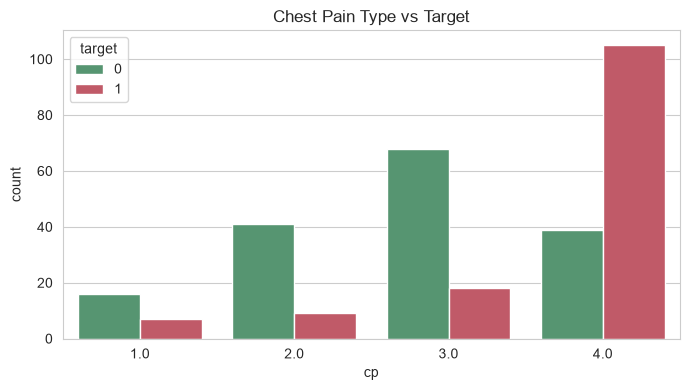

In [13]:
plt.figure(figsize=(7,4))
sns.countplot(x='cp', hue='target', data=df, palette=['#4C9F70','#D1495B'])
plt.title('Chest Pain Type vs Target'); plt.tight_layout()
plt.savefig('../images/eda/03_cp_vs_target.png', dpi=150); plt.show()

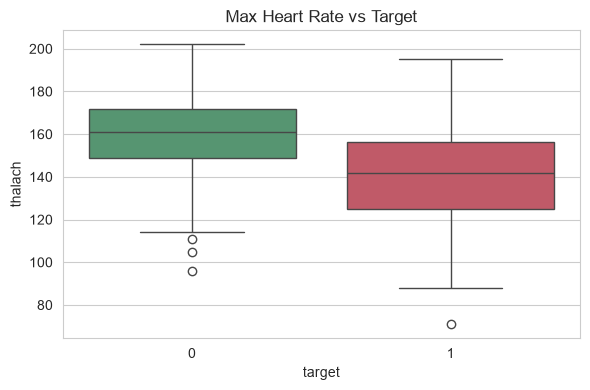

In [14]:
plt.figure(figsize=(6,4))
sns.boxplot(x='target', y='thalach', data=df, palette=['#4C9F70','#D1495B'])
plt.title('Max Heart Rate vs Target'); plt.tight_layout()
plt.savefig('../images/eda/04_thalach_vs_target.png', dpi=150); plt.show()

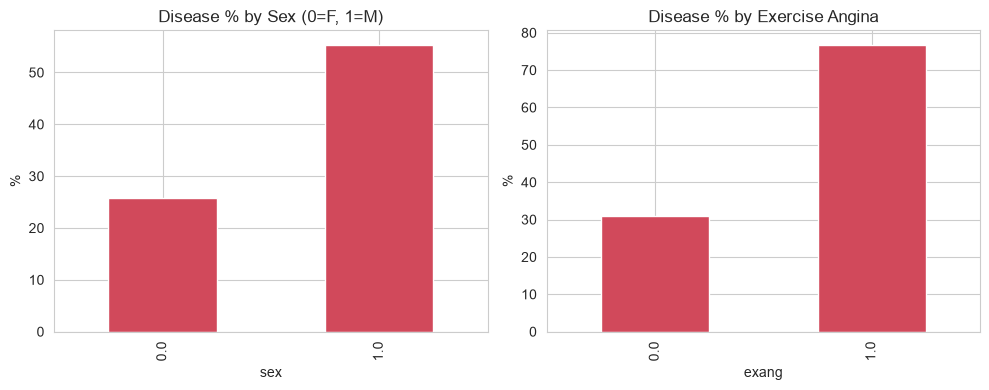

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))
(df.groupby('sex')['target'].mean()*100).plot(kind='bar', ax=ax[0], color='#D1495B')
ax[0].set_title('Disease % by Sex (0=F, 1=M)'); ax[0].set_ylabel('%')
(df.groupby('exang')['target'].mean()*100).plot(kind='bar', ax=ax[1], color='#D1495B')
ax[1].set_title('Disease % by Exercise Angina'); ax[1].set_ylabel('%')
plt.tight_layout(); plt.savefig('../images/eda/05_sex_exang_vs_target.png', dpi=150); plt.show()

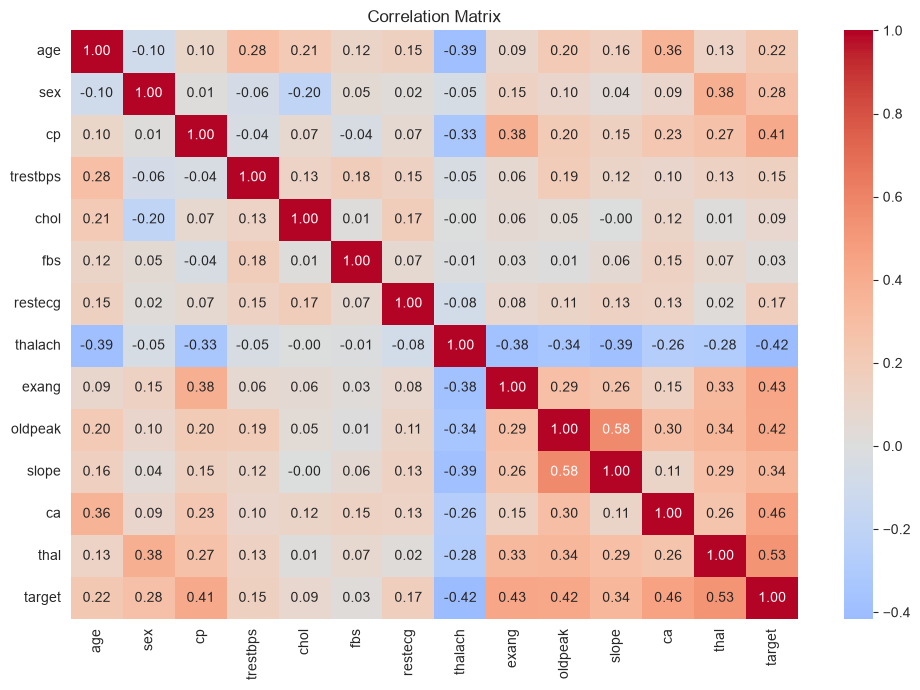

In [16]:
plt.figure(figsize=(10,7))
sns.heatmap(df.drop(columns='num').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix'); plt.tight_layout()
plt.savefig('../images/eda/06_correlation.png', dpi=150); plt.show()

In [17]:
#PREPROCESSING:X,y and Train-Test Split
from sklearn.model_selection import train_test_split

X = df.drop(columns=['num', 'target'])   # features ('num' drop karna zaroori: warna target leak hoga)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # stratify: dono sets mein same class ratio

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train target %:', y_train.mean().round(3), ' Test target %:', y_test.mean().round(3))

Train: (242, 13)  Test: (61, 13)
Train target %: 0.459  Test target %: 0.459


In [18]:
#Preprocessing Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features = ['age','trestbps','chol','thalach','oldpeak','ca']
cat_features = ['cp','restecg','slope','thal']
bin_features = ['sex','fbs','exang']

preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), num_features),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_features),
    ('bin', 'passthrough', bin_features)
])

In [19]:
#ML models:logistic Regression , Decision Tree , Random Forest
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(max_depth=4, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42)
}

pipes = {}
for name, model in models.items():
    pipes[name] = Pipeline([('prep', preprocess), ('model', model)])
    pipes[name].fit(X_train, y_train)          # fit(): train data se seekhna
    print(name, 'trained')

Logistic Regression trained
Decision Tree trained
Random Forest trained


In [20]:
#Model Evaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)
from sklearn.model_selection import cross_val_score

results = []
for name, pipe in pipes.items():
    y_pred  = pipe.predict(X_test)                    # predict(): 0/1 class
    y_proba = pipe.predict_proba(X_test)[:, 1]        # predict_proba(): disease ki probability
    cv = cross_val_score(pipe, X, y, cv=5, scoring='f1').mean()
    results.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1-score':  f1_score(y_test, y_pred),
        'ROC-AUC':   roc_auc_score(y_test, y_proba),
        'CV F1 (5-fold)': cv
    })

results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df

,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV F1 (5-fold)
Model,,,,,,
Logistic Regression,0.869,0.812,0.929,0.867,0.958,0.806
Decision Tree,0.787,0.742,0.821,0.780,0.860,0.721
Random Forest,0.885,0.818,0.964,0.885,0.946,0.795


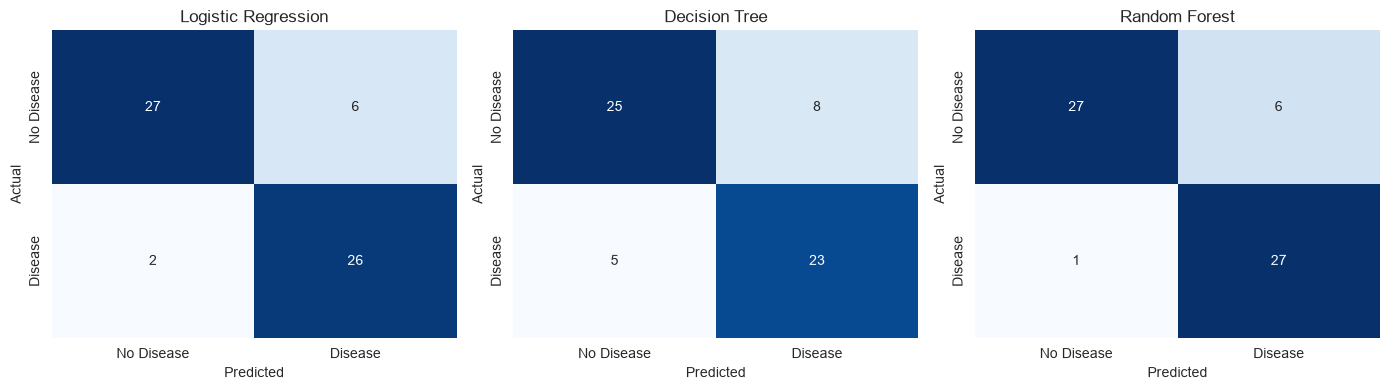

In [21]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, (name, pipe) in zip(axes, pipes.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No Disease','Disease'], yticklabels=['No Disease','Disease'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig('../images/eda/07_confusion_matrices.png', dpi=150); plt.show()

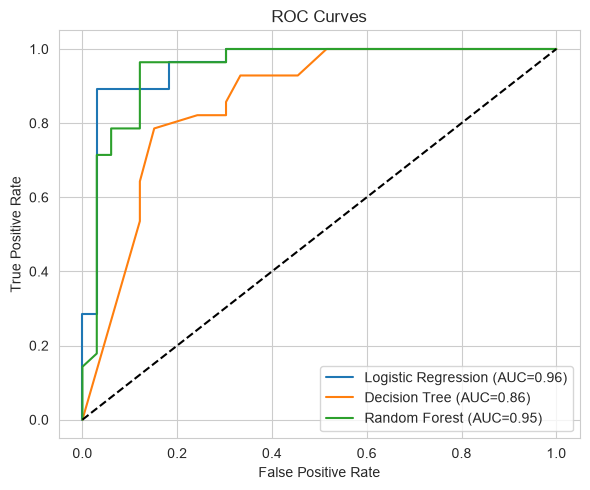

In [22]:
# ROC curves
plt.figure(figsize=(6,5))
for name, pipe in pipes.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, pipe.predict_proba(X_test)[:,1]):.2f})")
plt.plot([0,1],[0,1],'k--'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves'); plt.legend(); plt.tight_layout()
plt.savefig('../images/eda/08_roc_curves.png', dpi=150); plt.show()

In [23]:
best_name = results_df['F1-score'].idxmax()
print('Final model:', best_name)
final_pipe = pipes[best_name]
joblib.dump(final_pipe, '../models/final_model.pkl')
print('Saved: ../models/final_model.pkl')

Final model: Random Forest
Saved: ../models/final_model.pkl


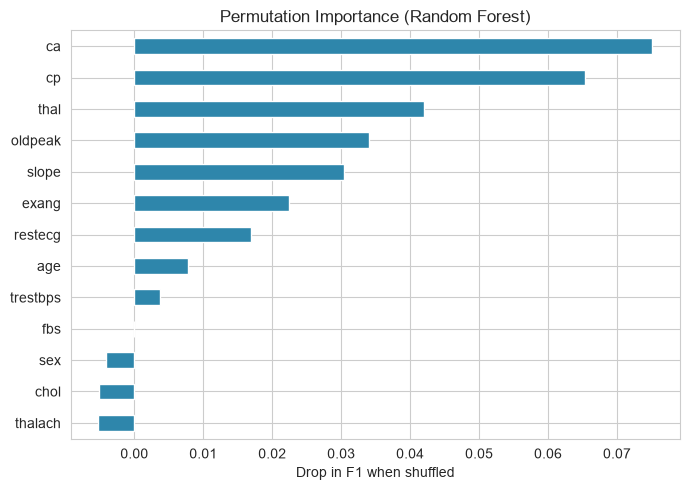

ca          0.075
cp          0.065
thal        0.042
oldpeak     0.034
slope       0.030
exang       0.022
restecg     0.017
age         0.008
trestbps    0.004
fbs         0.000
sex        -0.004
chol       -0.005
thalach    -0.005
dtype: float64

In [24]:
from sklearn.inspection import permutation_importance

r = permutation_importance(final_pipe, X_test, y_test, n_repeats=20,
                           random_state=42, scoring='f1')
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(7,5))
imp.plot(kind='barh', color='#2E86AB')
plt.title(f'Permutation Importance ({best_name})'); plt.xlabel('Drop in F1 when shuffled')
plt.tight_layout(); plt.savefig('../images/eda/09_feature_importance.png', dpi=150); plt.show()
imp.sort_values(ascending=False).round(3)

In [25]:
pbi = df.copy()
pbi['target_label'] = pbi['target'].map({0: 'No Disease', 1: 'Disease'})
pbi['sex_label']    = pbi['sex'].map({0: 'Female', 1: 'Male'})
pbi['cp_label']     = pbi['cp'].map({1:'Typical Angina', 2:'Atypical Angina', 3:'Non-anginal', 4:'Asymptomatic'})
pbi['exang_label']  = pbi['exang'].map({0: 'No', 1: 'Yes'})
pbi['fbs_label']    = pbi['fbs'].map({0: 'No', 1: 'Yes'})
pbi['age_group']    = pd.cut(pbi['age'], bins=[0,40,50,60,100], labels=['<=40','41-50','51-60','60+'])
pbi.to_csv('../data/processed/heart_clean.csv', index=False)
print('Saved:', pbi.shape)
pbi.head()

Saved: (303, 21)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,...,ca,thal,num,target,target_label,sex_label,cp_label,exang_label,fbs_label,age_group
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,...,0.0,6.0,0,0,No Disease,Male,Typical Angina,No,Yes,60+
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,...,3.0,3.0,2,1,Disease,Male,Asymptomatic,Yes,No,60+
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,...,2.0,7.0,1,1,Disease,Male,Asymptomatic,Yes,No,60+
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,...,0.0,3.0,0,0,No Disease,Male,Non-anginal,No,No,<=40
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,...,0.0,3.0,0,0,No Disease,Female,Atypical Angina,No,No,41-50
